<img src="logo.png" alt="Vegeta" width="240">

# Svarog — a CW diode-end-pumped Nd:YAG laser, designed on Hyperion

**Svarog** is a 1064 nm continuous-wave laser: a Ø3 × 10 mm Nd:YAG rod pumped end-on at 808 nm by a 30 W fibre-coupled
diode, in a cavity whose mirrors, spacings and output coupler this notebook chooses. Everything is computed with
**Hyperion** (`vegeta.hyperion`, [docs/hyperion.md](../docs/hyperion.md)): the pump imaged onto the rod and its radius
inside it, the four-level laser's threshold, slope and output, the pump's thermal lens, the cavity's eigenmode and
stability window over the pump power — re-solved at every pump power, since the lens moves with it — the beam that leaves
the coupler and the lens train that puts it on a work spot. The device as numbers is `designs/svarog.py` (`import svarog as sv`);
the drawings are `designs/svarog_drawings.py`.

Four cavity revisions are compared at the 20 W design pump: **A** the textbook plano–concave layout, **B** a compact
cavity with the HR coating on the rod's face, **C** a folded cavity with a concave fold mirror at an angle, **D** a
zone-II cavity that is unstable cold and opens above 13 W. The record goes to `designs/data/svarog_design.json` (the chosen
cavity, the beam, the delivery train as Hyperion objects) and `designs/data/reports/46_svarog.json`.

What is *not* here: apertures and diffraction, lens aberrations, the rod's real temperature field and stress, the mounts
and the build, pulses and frequency conversion — the roadmap of [`svarog_todo.md`](../svarog_todo.md), in the order it is needed.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
from vegeta import hyperion as hy
import svarog as sv, svarog_drawings as svd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
OUT = Path("output/46_svarog"); OUT.mkdir(parents=True, exist_ok=True)
DATA = Path("designs/data")
from vegeta import yanus
GATE = yanus.enter("46_svarog", debug=DEBUG)        # the door keeper (workflows/flow.py): needs vegeta.hyperion, gives the design and the report
PUMP_DESIGN = 20.0                                  # W incident on the rod: the work point; the diode goes to 30 W

## 1. The rod and its pump

The medium's numbers (Koechner's for 1 at.% Nd:YAG), the rod, how much of the pump it absorbs and where the heat sits
(the absorption-weighted centroid, 2.3 mm in). The pump: a 200 µm-core, NA 0.22 fibre, whose beam has M² = π r NA/λ ≈ 85,
imaged onto the rod's entrance face by a 25 mm collimator and a focusing lens. The spot on the face is the core radius
times the magnification; inside the rod the beam diverges at NA/n and its radius grows along the absorption length — the
*effective* pump radius (the absorption-weighted mean of w_p²) is what the gain and the thermal lens see. The table over the
magnification shows the trade: a small spot on the face is a large effective radius (the beam diverges before it is absorbed);
beyond M ≈ 4 the effective radius is the face spot. Magni's rule gives the largest TEM₀₀ mode a cavity that stays stable from
0 to 30 W can hold, w² = 2λ/(π ΔD), where ΔD is the dioptric swing of the thermal lens over that range: a larger pump spot
means a weaker lens and a larger mode cap.

medium                      Nd:YAG 1.0 at.%
σ [cm²]                             2.8e-19
τ [µs]                                230.0
λ laser [nm]                         1064.0
λ pump [nm]                           808.0
α pump [1/cm]                           4.0
η_q                                     0.9
η_heat                                  0.3
n (1064)                           1.814653
dn/dT [1/K]                         7.3e-06
κ [W/m/K]                              13.0
I_sat [kW/cm²]                     2.899007
rod Ø × L [mm]                       3 × 10
pump absorbed                      0.981684
absorption centroid [mm]           2.313426
Name: Svarog's rod, dtype: object

pump fibre: core radius 100 µm, NA 0.22, M² 86; collimator f 25 mm, focusing lens f 100 mm: magnification 4.0


,spot on the face [µm],effective radius [µm],radius at the exit [µm],Rayleigh range in the rod [mm],thermal lens f at 20 W [mm],f at 30 W [mm],"Magni mode cap, 0–30 W window [µm]",threshold at that mode [W]
magnification,,,,,,,,
1.5,150.0,293.9,821.7,1.9,68.4,45.6,175.7,0.4
2.0,200.0,277.2,641.3,3.3,60.8,40.5,165.7,0.4
3.0,300.0,328.9,512.8,7.4,85.6,57.1,196.7,0.6
4.0,400.0,415.1,516.2,13.2,136.4,90.9,248.2,0.9
5.0,500.0,510.1,572.8,20.6,205.9,137.3,304.9,1.3
6.0,600.0,607.8,651.7,29.5,292.4,195.0,363.4,1.9


chosen: magnification 4 → 400 µm on the face, effective pump radius 415 µm


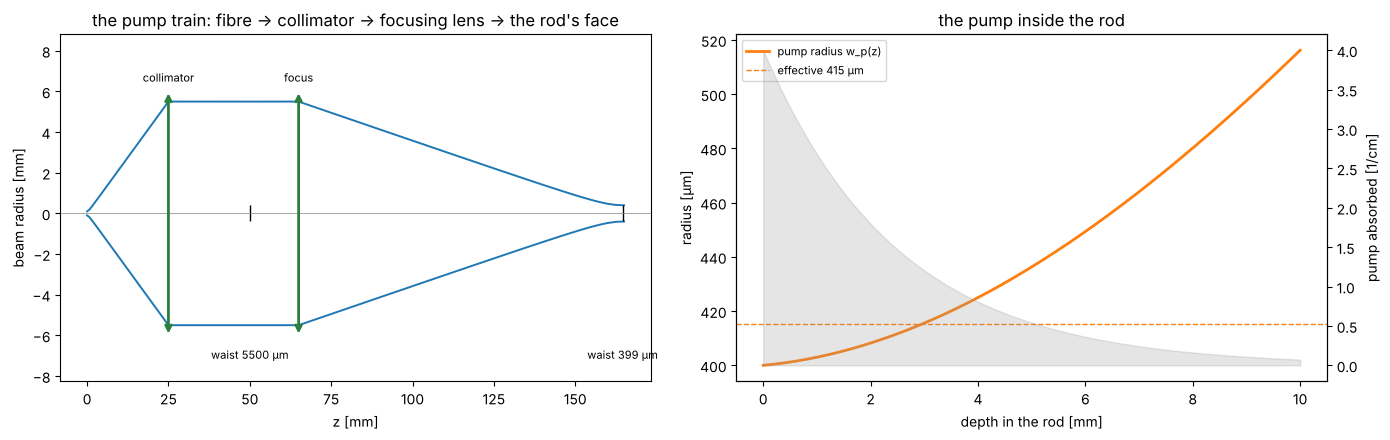

In [3]:
m = sv.ROD.medium
display(pd.Series({"medium": m.name, "σ [cm²]": f"{m.sigma * 1e4:.1e}", "τ [µs]": m.tau * 1e6, "λ laser [nm]": m.wavelength * 1e9, "λ pump [nm]": m.pump_wavelength * 1e9,
                   "α pump [1/cm]": m.alpha_pump / 100, "η_q": m.eta_q, "η_heat": m.eta_heat, "n (1064)": m.n(), "dn/dT [1/K]": f"{m.material.dn_dT:.1e}",
                   "κ [W/m/K]": m.material.kappa, "I_sat [kW/cm²]": m.saturation_intensity / 1e7,
                   "rod Ø × L [mm]": f"{2 * sv.ROD.radius * 1e3:.0f} × {sv.ROD.length * 1e3:.0f}", "pump absorbed": sv.ROD.absorbed_fraction,
                   "absorption centroid [mm]": sv.absorption_centroid() * 1e3}, name="Svarog's rod"))
fibre = sv.PUMP.beam()
print(f"pump fibre: core radius {sv.PUMP.core_radius * 1e6:.0f} µm, NA {sv.PUMP.NA}, M² {fibre.m2:.0f}; collimator f {sv.PUMP.f_collimator * 1e3:.0f} mm, "
      f"focusing lens f {sv.PUMP.f_focus * 1e3:.0f} mm: magnification {sv.PUMP.magnification:.1f}")
rows = {}
for M in (1.5, 2, 3, 4, 5, 6):
    p = sv.pump_in_rod(sv.PUMP.with_magnification(M))
    f30 = sv.thermal_lens(sv.PUMP.power_max, p["w_effective"]).f
    cap = math.sqrt(2 * sv.LAM / (math.pi / f30))
    rows[M] = {"spot on the face [µm]": p["w_face"] * 1e6, "effective radius [µm]": p["w_effective"] * 1e6, "radius at the exit [µm]": p["w_exit"] * 1e6,
               "Rayleigh range in the rod [mm]": p["rayleigh_in_rod"] * 1e3, "thermal lens f at 20 W [mm]": sv.thermal_lens(PUMP_DESIGN, p["w_effective"]).f * 1e3,
               "f at 30 W [mm]": f30 * 1e3, "Magni mode cap, 0–30 W window [µm]": cap * 1e6,
               "threshold at that mode [W]": hy.Laser(sv.ROD, p["w_effective"], cap, 0.10, sv.LOSS_ROUND_TRIP).threshold()}
MAG = pd.DataFrame(rows).T; MAG.index.name = "magnification"
display(MAG.round(1))
PR = sv.pump_in_rod(sv.PUMP)
W_PUMP = PR["w_effective"]
print(f"chosen: magnification {sv.PUMP.magnification:.0f} → {PR['w_face'] * 1e6:.0f} µm on the face, effective pump radius {W_PUMP * 1e6:.0f} µm")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
svd.train_view(PR["trace"], ax=axs[0], title="the pump train: fibre → collimator → focusing lens → the rod's face", scale_w=1e3, unit="mm")
svd.pump_view(PR, sv.ROD, ax=axs[1])
plt.tight_layout(); plt.savefig(OUT / "pump.png", dpi=110); plt.show()

## 2. Threshold, slope, output and the coupler

The four-level steady state on the effective area π(w_p² + w_l²)/2 (Fan & Byer, Laporta & Brussard): the threshold pump
P_th = π hν_p (w_p² + w_l²)(T + L)/(4 σ τ η_abs η_q), the slope η_s = η_abs η_q (λ_p/λ_l) T/(T + L), the output η_s (P − P_th).
The mode radius is a placeholder here (Magni's cap from the table above); § 4 replaces it with the mode each cavity has. The
output coupler: the output against T at 20 W (a scan) against Rigrod's T_opt = √(g₀L) − L; with a 1.2 % round-trip loss and a
small-signal gain of several nepers the optimum is a strong coupler, and the curve is flat around it — 10 % is chosen,
a stock value that keeps the intracavity power (and the coatings' load) moderate.

,threshold [W],slope,output at 20 W [W],intracavity at 20 W [W]
T,,,,
0.03,0.333,0.479,9.425,314.169
0.05,0.492,0.541,10.555,211.106
0.08,0.730,0.583,11.242,140.530
0.10,0.889,0.599,11.448,114.484
0.15,1.286,0.621,11.626,77.506
0.20,1.683,0.633,11.594,57.970


optimum coupler at 20 W: T = 0.162 (Rigrod 0.162) for 11.63 W; small-signal gain g0 = 2.52 nepers per round trip; chosen T = 0.10


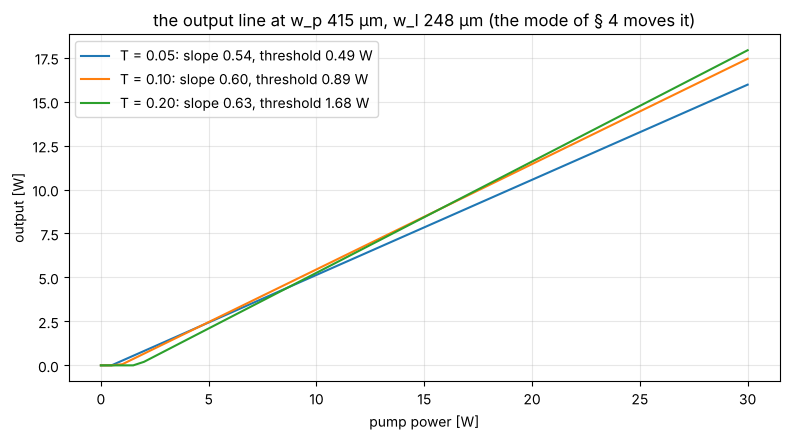

In [4]:
W_MODE_GUESS = float(MAG.loc[sv.PUMP.magnification, "Magni mode cap, 0–30 W window [µm]"]) * 1e-6
L0 = hy.Laser(sv.ROD, W_PUMP, W_MODE_GUESS, 0.10, sv.LOSS_ROUND_TRIP)
COUP = pd.DataFrame({T: {"threshold [W]": L0.threshold(T), "slope": L0.slope_efficiency(T), "output at 20 W [W]": float(L0.output(PUMP_DESIGN, T)),
                         "intracavity at 20 W [W]": L0.intracavity(PUMP_DESIGN, T)} for T in sv.T_CANDIDATES}).T
COUP.index.name = "T"; display(COUP.round(3))
OPT = L0.optimum_coupler(PUMP_DESIGN)
print(f"optimum coupler at {PUMP_DESIGN:.0f} W: T = {OPT['T_opt']:.3f} (Rigrod {OPT['T_opt_rigrod']:.3f}) for {OPT['P_out']:.2f} W; "
      f"small-signal gain g0 = {OPT['g0']:.2f} nepers per round trip; chosen T = 0.10")
pumps = np.linspace(0, sv.PUMP.power_max, 61)
fig, ax = plt.subplots(figsize=(8, 4.5))
for T in (0.05, 0.10, 0.20):
    ax.plot(pumps, L0.output(pumps, T), label=f"T = {T:.2f}: slope {L0.slope_efficiency(T):.2f}, threshold {L0.threshold(T):.2f} W")
ax.set_xlabel("pump power [W]"); ax.set_ylabel("output [W]"); ax.set_title(f"the output line at w_p {W_PUMP * 1e6:.0f} µm, w_l {W_MODE_GUESS * 1e6:.0f} µm (the mode of § 4 moves it)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.savefig(OUT / "output_line.png", dpi=110); plt.show()

## 3. The thermal lens

Innocenti's end-pumped lens, 1/f = η_h P_abs (dn/dT)/(π κ w_p²), plus 20 % for the stress-induced index change and the
end-face bulging (the Nd:YAG literature's share; Hyperion takes it as a stated fraction, never a default). At the design
pump it is a lens of a few centimetres' focal length sitting 2.3 mm inside the rod — the element that decides the
cavity. The rod's centre-to-barrel temperature rise (steady radial conduction, the heat inside the pump radius) says how
hot the crystal runs; its fracture and depolarisation limits are stage S.2.

,heat [W],"f, dn/dT only [mm]",f with stress and bulge [mm],dioptres,ΔT centre–barrel [K]
pump [W],,,,,
5,1.47,654.77,545.64,1.83,3.22
10,2.95,327.38,272.82,3.67,6.43
15,4.42,218.26,181.88,5.50,9.65
20,5.89,163.69,136.41,7.33,12.87
25,7.36,130.95,109.13,9.16,16.09
30,8.84,109.13,90.94,11.00,19.30


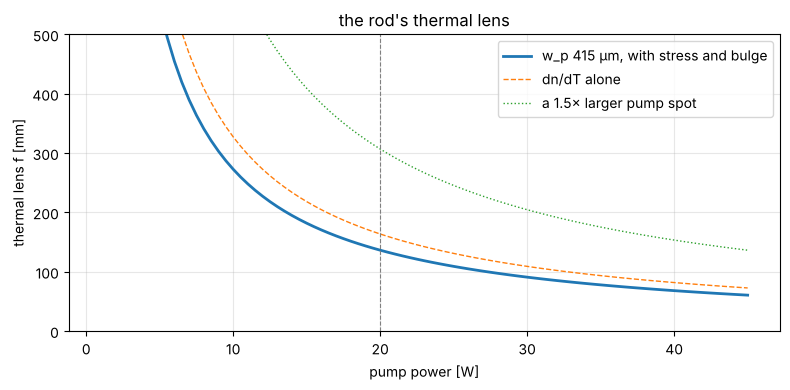

In [5]:
TL = pd.DataFrame({P: {"heat [W]": sv.ROD.medium.eta_heat * sv.ROD.absorbed_fraction * P, "f, dn/dT only [mm]": hy.thermal_lens(sv.ROD, P, W_PUMP).f * 1e3,
                       "f with stress and bulge [mm]": sv.thermal_lens(P, W_PUMP).f * 1e3, "dioptres": 1 / sv.thermal_lens(P, W_PUMP).f,
                       "ΔT centre–barrel [K]": hy.rod_temperature_rise(sv.ROD, P, W_PUMP)["dT_centre_to_barrel"]} for P in (5, 10, 15, 20, 25, 30)}).T
TL.index.name = "pump [W]"; display(TL.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
pp = np.linspace(1, 45, 89)
ax.plot(pp, [sv.thermal_lens(P, W_PUMP).f * 1e3 for P in pp], lw=2, label=f"w_p {W_PUMP * 1e6:.0f} µm, with stress and bulge")
ax.plot(pp, [hy.thermal_lens(sv.ROD, P, W_PUMP).f * 1e3 for P in pp], lw=1, ls="--", label="dn/dT alone")
ax.plot(pp, [sv.thermal_lens(P, 1.5 * W_PUMP).f * 1e3 for P in pp], lw=1, ls=":", label=f"a 1.5× larger pump spot")
ax.set_ylim(0, 500); ax.axvline(PUMP_DESIGN, color="grey", lw=0.8, ls="--")
ax.set_xlabel("pump power [W]"); ax.set_ylabel("thermal lens f [mm]"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("the rod's thermal lens")
plt.tight_layout(); plt.savefig(OUT / "thermal_lens.png", dpi=110); plt.show()

## 4. The cavities on Hyperion

Each revision is a `Train` from the HR to the output coupler with the rod split at the absorption centroid around the
thermal lens; Hyperion solves the round trip for the self-reproducing Gaussian in both planes, puts its spot on every element
and sweeps the pump power for the stability window. The drawings show the mode envelope at the design pump; the table
compares the revisions there: the mode in the rod against the pump radius (a top-hat pump: the share inside the mode is
the square of the ratio — pump outside the TEM₀₀ mode feeds higher-order modes), the astigmatism of the folded cavity, the
window, the threshold and output, the spectrum, the beam out.

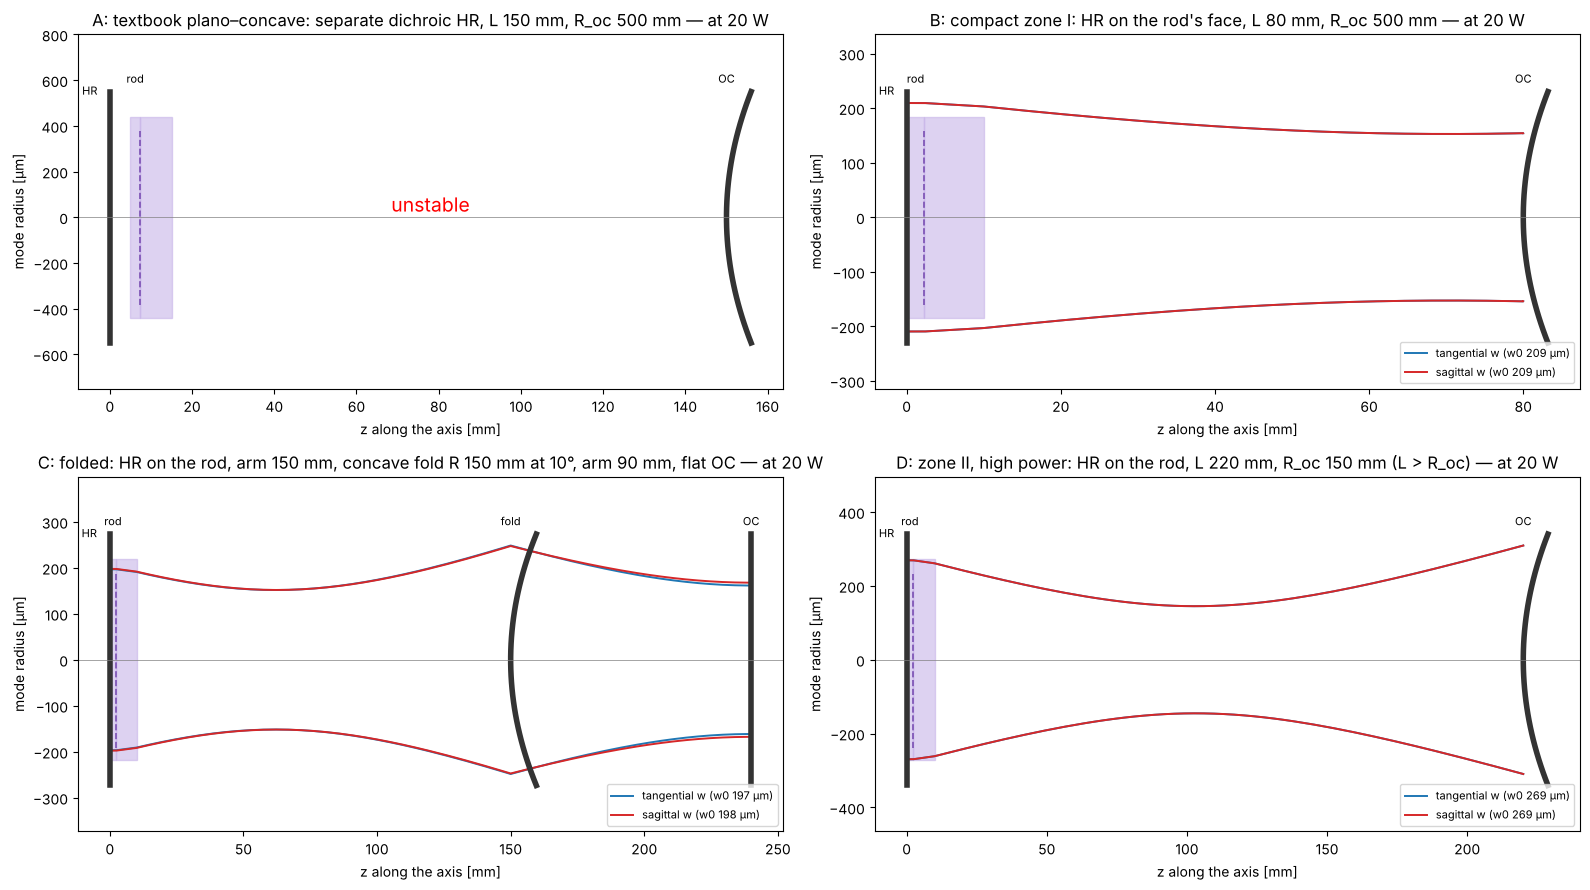

,title,length [mm],T,stable,mode in rod [µm],pump radius [µm],mode / pump,pump inside the mode,astigmatism w_t/w_s,spot on OC [µm],...,output [W],thermal lens f [mm],stable from 0 W,window from [W],window to [W],FSR [MHz],linewidth [MHz],modes under the gain line,beam out w0 [µm],beam out divergence [mrad]
A,"textbook plano–concave: separate dichroic HR, L 150 mm, R_oc 500 mm",150.0,0.1,False,NaN,415.135323,NaN,NaN,NaN,NaN,...,0.0,136.409737,True,NaN,NaN,947.83126,17.868559,126.604814,NaN,NaN
B,"compact zone I: HR on the rod's face, L 80 mm, R_oc 500 mm",80.0,0.1,True,209.369779,415.135323,0.504341,0.25436,1.0,154.124271,...,11.382857,136.409737,True,0.0,36.5,1700.534569,32.058557,70.566046,153.667,2.203998
C,"folded: HR on the rod, arm 150 mm, concave fold R 150 mm at 10°, arm 90 mm, flat OC",240.0,0.1,True,197.202708,415.135323,0.475032,0.225656,0.99554,161.453884,...,11.39412,136.409737,True,0.0,38.5,604.063358,11.484061,198.654658,161.453884,2.097699
D,"zone II, high power: HR on the rod, L 220 mm, R_oc 150 mm (L > R_oc)",220.0,0.1,True,269.390439,415.135323,0.648922,0.4211,1.0,309.316481,...,11.31743,136.409737,False,13.0,42.0,657.017339,12.386122,182.643582,214.763204,1.577001


In [6]:
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, rev in zip(axs.flat, sv.REVISIONS.values()):
    svd.cavity_view(sv.cavity(rev, PUMP_DESIGN, W_PUMP), ax=ax, title=f"{rev.name}: {rev.title} — at {PUMP_DESIGN:.0f} W")
plt.tight_layout(); plt.savefig(OUT / "cavities.png", dpi=110); plt.show()
CMP = pd.DataFrame(sv.compare(sv.REVISIONS.values(), PUMP_DESIGN, W_PUMP))
display(CMP.T.rename(columns=lambda c: c))

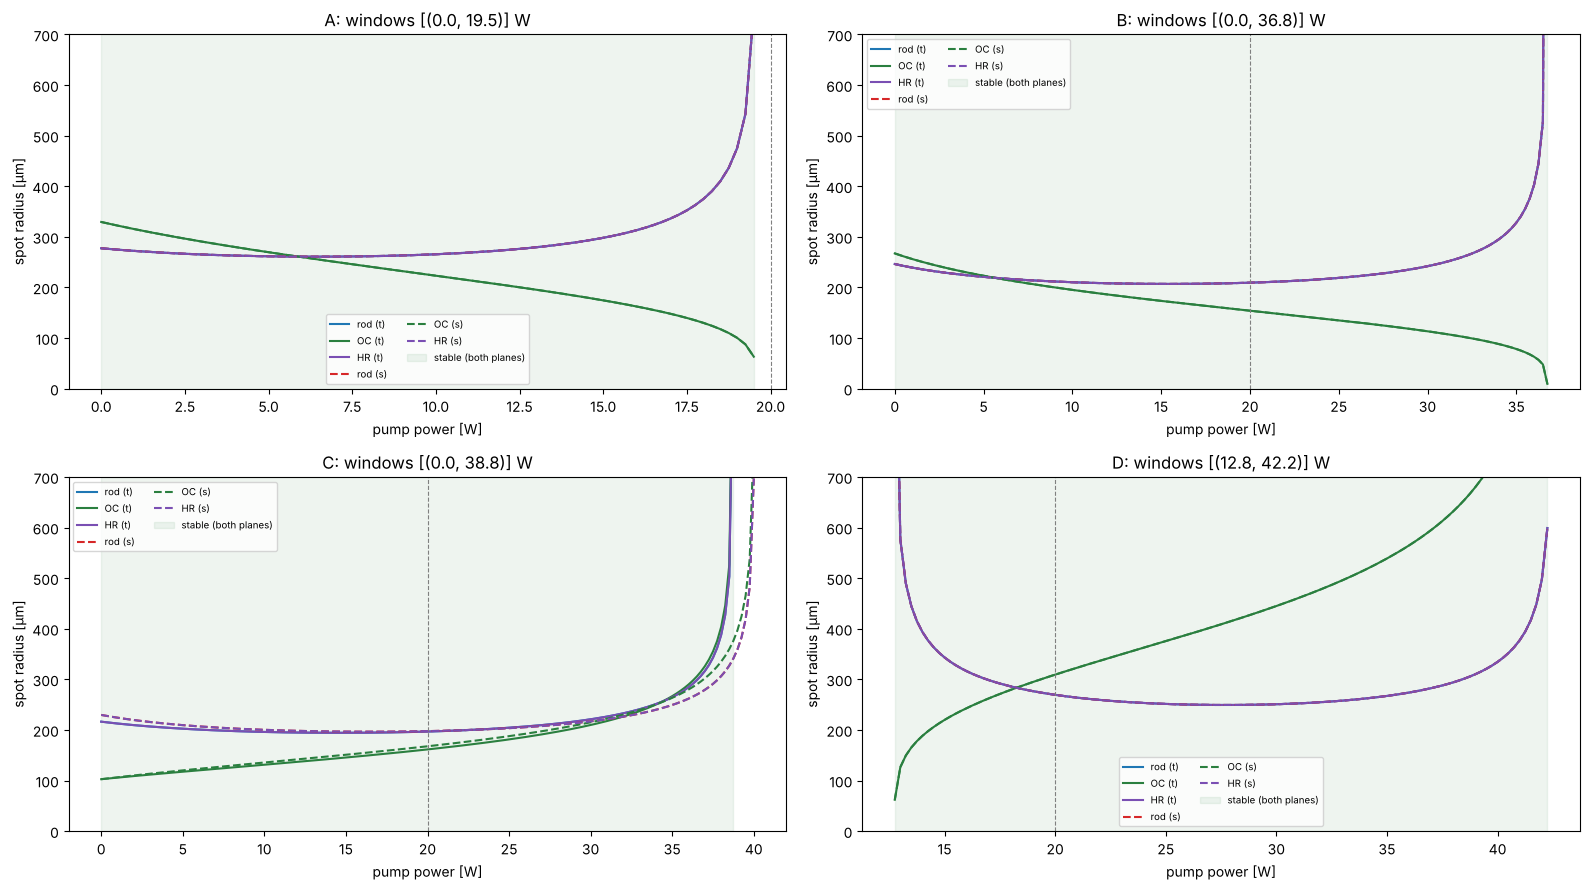

In [7]:
WIN = {name: sv.stability_window(rev, W_PUMP, np.linspace(0, 45, 181)) for name, rev in sv.REVISIONS.items()}
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, (name, win) in zip(axs.flat, WIN.items()):
    svd.stability_view(win, ax=ax, title=f"{name}: windows {[(round(a, 1), round(b, 1) if b != math.inf else 'inf') for a, b in win['windows']]} W")
    ax.axvline(PUMP_DESIGN, color="grey", lw=0.8, ls="--"); ax.set_ylim(0, 700)
plt.tight_layout(); plt.savefig(OUT / "stability.png", dpi=110); plt.show()

**Reading the four.** The textbook cavity **A** is stable cold with a 280 µm mode — and closes at 19.5 W, before the
design pump: a long arm behind a lens of 136 mm focal length is past the concentric point. **B** and **C** are stable
from cold to beyond the diode's 30 W, but their mode in the rod is half the pump spot — Magni's rule: a window that spans the
whole dioptric swing of the lens (0 to 11 D) can only hold w² = 2λ/(π ΔD), ≈ 250 µm, whatever the mirrors; only a quarter
of the pump lies inside the TEM₀₀ mode, the rest feeds higher-order modes. **C** buys a nearly collimated second arm for the later Q-switch or doubling crystal
at the price of a 10° fold's astigmatism (a few per cent at this radius). **D** is the high-power design: with L > R_oc it is
unstable cold and the thermal lens opens it at 13 W; inside its window the mode is two thirds of the pump spot, 42 % of the
pump inside it (the window's dioptric width is what it holds), and it stays open to 42 W. Svarog takes **D** for the 15–30 W work range, with **B**
recorded as the fallback that lases at any pump. The output powers hardly differ — the threshold is a watt against twenty —
but the beam quality at the work spot does, and that is what the mode-to-pump ratio buys.

In [8]:
CHOSEN = "D"
REV = sv.REVISIONS[CHOSEN]
OP = sv.operating_point(REV, PUMP_DESIGN, W_PUMP)
print(f"{CHOSEN}: {REV.title}\n  mode in the rod {OP['w_rod'] * 1e6:.0f} µm (t {OP['w_rod_t'] * 1e6:.0f}, s {OP['w_rod_s'] * 1e6:.0f}) against the pump's {W_PUMP * 1e6:.0f} µm: "
      f"{OP['pump_inside_mode']:.0%} of the pump inside the mode\n  threshold {OP['threshold_W']:.2f} W, slope {OP['slope_efficiency']:.2f}, "
      f"output {OP['output_W']:.1f} W at {PUMP_DESIGN:.0f} W, {OP['intracavity_W']:.0f} W circulating; thermal lens f {OP['f_thermal'] * 1e3:.0f} mm; "
      f"rod ΔT {OP['rod_dT_centre_to_barrel']:.0f} K")

D: zone II, high power: HR on the rod, L 220 mm, R_oc 150 mm (L > R_oc)
  mode in the rod 269 µm (t 269, s 269) against the pump's 415 µm: 42% of the pump inside the mode
  threshold 0.94 W, slope 0.59, output 11.3 W at 20 W, 113 W circulating; thermal lens f 136 mm; rod ΔT 13 K


## 5. The power curve and the spectrum

The output against the pump with the cavity re-solved at every point: the mode shrinks or grows with the thermal lens,
the threshold follows it, and a cavity outside its window gives nothing. B and C lase from threshold; D switches on when
its window opens and its mode is then the right size. The chosen cavity's spectrum: the free spectral range, how many
longitudinal modes fit under Nd:YAG's 120 GHz gain line (a free-running CW laser runs on several), the photon lifetime
and the cold-cavity linewidth, the transverse-mode spacing from the round-trip Gouy phase.

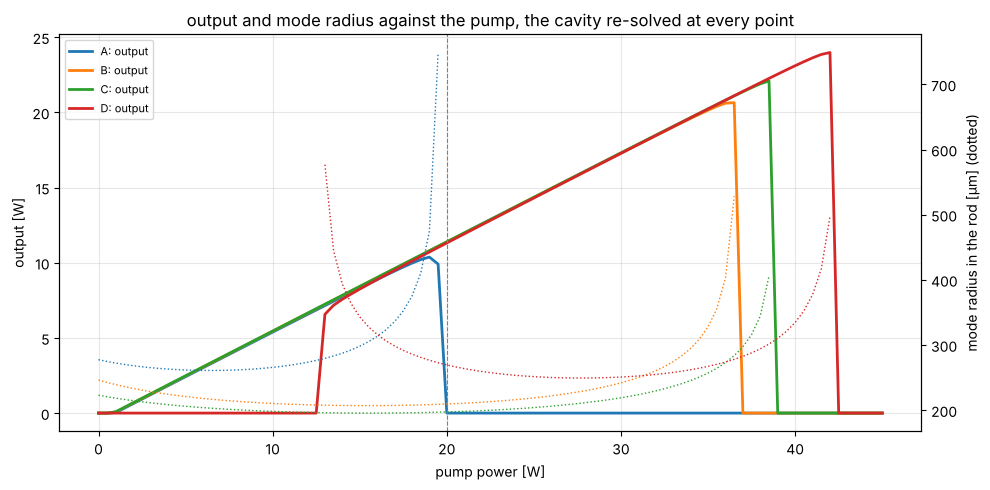

,lases from [W],output at 20 W [W],output at 30 W [W],mode at 20 W [µm],mode at 30 W [µm]
A,1.0,0.00,0.00,NaN,NaN
B,1.0,11.38,17.29,209.37,241.93
C,1.0,11.39,17.31,197.20,218.98
D,13.0,11.32,17.28,269.39,250.80


optical length [mm]                       2.281470e+02
FSR [MHz]                                 6.570170e+02
longitudinal modes under the gain line    1.826440e+02
round-trip survival                       8.880000e-01
photon lifetime [ns]                      1.285100e+01
finesse                                   5.304500e+01
cold-cavity linewidth [MHz]               1.238600e+01
Q                                         2.275135e+07
round-trip Gouy phase [rad]               4.182000e+00
transverse mode spacing [MHz]             4.372590e+02
Name: spectrum of D at 20 W, dtype: float64

In [9]:
pumps = np.linspace(0, 45, 91)
CURVES = {name: sv.power_curve(rev, W_PUMP, pumps) for name, rev in sv.REVISIONS.items()}
fig, ax = plt.subplots(figsize=(10, 5)); svd.power_view(CURVES, ax=ax, pump_design=PUMP_DESIGN); ax.set_title("output and mode radius against the pump, the cavity re-solved at every point")
plt.tight_layout(); plt.savefig(OUT / "power_curves.png", dpi=110); plt.show()
PC = pd.DataFrame({name: {"lases from [W]": float(c["pump_W"][np.argmax(c["output_W"] > 0)]) if (c["output_W"] > 0).any() else math.nan,
                          "output at 20 W [W]": float(np.interp(20, c["pump_W"], c["output_W"])), "output at 30 W [W]": float(np.interp(30, c["pump_W"], c["output_W"])),
                          "mode at 20 W [µm]": float(np.interp(20, c["pump_W"], c["w_rod"])) * 1e6, "mode at 30 W [µm]": float(np.interp(30, c["pump_W"], c["w_rod"])) * 1e6}
                   for name, c in CURVES.items()}).T
display(PC.round(2))
SPEC = OP["resonator"].spectrum()
display(pd.Series({"optical length [mm]": SPEC["optical_length"] * 1e3, "FSR [MHz]": SPEC["fsr"] / 1e6, "longitudinal modes under the gain line": sv.ND_LINEWIDTH_HZ / SPEC["fsr"],
                   "round-trip survival": SPEC["survival"], "photon lifetime [ns]": SPEC["photon_lifetime"] * 1e9, "finesse": SPEC["finesse"],
                   "cold-cavity linewidth [MHz]": SPEC["linewidth"] / 1e6, "Q": SPEC["Q"], "round-trip Gouy phase [rad]": SPEC.get("gouy_round_trip", math.nan),
                   "transverse mode spacing [MHz]": SPEC.get("transverse_mode_spacing", math.nan) / 1e6}, name=f"spectrum of {CHOSEN} at {PUMP_DESIGN:.0f} W").round(3))

## 6. The beam out and the delivery train

The mode on the output coupler leaves through its substrate — a concave inner face and a flat outer face, a weak negative
lens in fused silica whose cardinal points Hyperion gives — and is a Gaussian with a virtual waist behind the coupler. The
delivery train: a collimating lens one focal length from that waist, sized for a 1 mm collimated radius, a 150 mm stand-off,
a 50 mm focusing lens and the work spot: its radius, the depth of focus (2 z_R) and where it sits. All with M² = 1 — the
paraxial TEM₀₀; the beam-quality budget of the real laser is the FFT stage (S.6).

OC substrate: OC substrate, -334 mm focal length (negative: diverging)
beam out: 309 µm on the coupler, waist 215 µm at +137 mm from the outer face, half-angle divergence 1.58 mrad, Rayleigh range 136 mm


collimator f [mm]                       634.115
collimator from the OC [mm]             771.134
collimated radius [mm]                    1.013
focusing lens f [mm]                     50.000
work spot radius [µm]                    16.664
work spot from the lens [mm]             49.852
depth of focus 2 z_R [mm]                 1.640
intensity at the work spot [kW/cm²]    1297.353
Name: delivery, dtype: float64

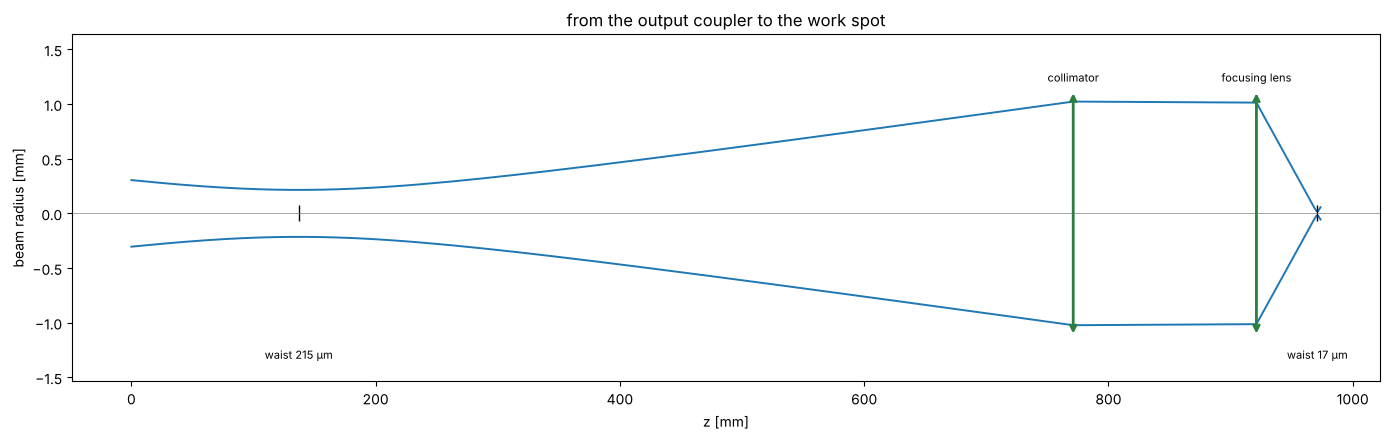

In [10]:
OB = sv.output_beam(OP["resonator"])
cp = OB["substrate"].cardinal_points(sv.LAM) if isinstance(OB["substrate"], hy.ThickLens) else {}
print(f"OC substrate: {OB['substrate'].name}, {cp.get('f', math.nan) * 1e3:.0f} mm focal length (negative: diverging)" if cp else "OC substrate: a flat plate")
print(f"beam out: {OB['w_oc'] * 1e6:.0f} µm on the coupler, waist {OB['w0'] * 1e6:.0f} µm at {OB['z0'] * 1e3:+.0f} mm from the outer face, "
      f"half-angle divergence {OB['divergence'] * 1e3:.2f} mrad, Rayleigh range {OB['rayleigh_range'] * 1e3:.0f} mm")
DL = sv.delivery_train(OB["beam"])
display(pd.Series({"collimator f [mm]": DL["f_collimator"] * 1e3, "collimator from the OC [mm]": DL["collimator_at"] * 1e3, "collimated radius [mm]": DL["w_collimated"] * 1e3,
                   "focusing lens f [mm]": 50.0, "work spot radius [µm]": DL["work_spot"] * 1e6, "work spot from the lens [mm]": DL["work_distance"] * 1e3,
                   "depth of focus 2 z_R [mm]": DL["depth_of_focus"] * 1e3, "intensity at the work spot [kW/cm²]": OP["output_W"] / (math.pi * DL["work_spot"] ** 2) / 1e7},
                  name="delivery").round(3))
fig, ax = plt.subplots(figsize=(14, 4.5)); svd.train_view(DL["trace"], ax=ax, title="from the output coupler to the work spot", scale_w=1e3, unit="mm")
plt.tight_layout(); plt.savefig(OUT / "delivery.png", dpi=110); plt.show()

## 7. The record

The chosen cavity (at the design pump and cold), the pump, the laser's numbers, the beam and the delivery train as Hyperion
objects in `designs/data/svarog_design.json` (`hyperion.load_design` reads them back); the tables of this notebook in
`designs/data/reports/46_svarog.json`. The exit gate checks both were written by this run and stamps them.

In [11]:
def _j(o):
    if hasattr(o, "tolist"):
        return o.tolist()
    if hasattr(o, "to_dict"):
        return o.to_dict()
    if isinstance(o, float) and not math.isfinite(o):
        return None if math.isnan(o) else ("inf" if o > 0 else "-inf")
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return str(o)

REC = sv.design_record(REV, sv.PUMP, PUMP_DESIGN, W_PUMP)
hy.save_design(DATA / "svarog_design.json", REC, notes=f"Svarog revision {CHOSEN} at {PUMP_DESIGN:.0f} W pump (notebook 46)")
REPORT = {"meta": {"notebook": "46_svarog", "chosen": CHOSEN, "design_pump_W": PUMP_DESIGN, "wavelength": sv.LAM, "pump_wavelength": sv.LAM_P, "debug": DEBUG},
          "rod": sv.ROD.to_dict(), "pump": {**REC["pump"], "magnifications": MAG.to_dict(orient="index")},
          "coupler": {"table": COUP.to_dict(orient="index"), "optimum": OPT, "chosen_T": REV.T},
          "thermal_lens": TL.to_dict(orient="index"),
          "revisions": {k: {**v, **{"windows": WIN[k]["windows"]}} for k, v in sv.compare(sv.REVISIONS.values(), PUMP_DESIGN, W_PUMP).items()},
          "laser": REC["laser"], "power_curves": PC.to_dict(orient="index"), "spectrum": SPEC,
          "beam_out": REC["beam_out"].to_dict(), "delivery": {k: v for k, v in DL.items() if k not in ("train", "trace")}}
(DATA / "reports").mkdir(parents=True, exist_ok=True)
(DATA / "reports" / "46_svarog.json").write_text(json.dumps(REPORT, indent=1, default=_j))
print("written", DATA / "svarog_design.json", "and", DATA / "reports" / "46_svarog.json")

written designs/data/svarog_design.json and designs/data/reports/46_svarog.json


In [12]:
STAMPS = GATE.leave()          # svarog_design.json and the report, written by this run and stamped

## 8. Reading it

- **The pump decides the cavity.** A 200 µm fibre at NA 0.22 cannot be focused tighter than ≈ 280 µm *effective* radius
  in a 10 mm rod, and a larger spot is the better design: the thermal lens weakens with w_p², every window widens, and the
  threshold stays at a watt. Magnification 4 (a 400 µm spot) is the choice; a 100 µm fibre would move every number.
- **Magni's rule, not the mirrors, sets the TEM₀₀ mode** of a cavity that must lase from cold: w² = 2λ/(π ΔD). To fill the
  pump the window must be narrow in dioptres — a zone-II cavity that the lens itself opens (D). Its price: nothing below 13 W,
  and a mode that changes with the pump; its reward: a mode two thirds of the pump spot (42 % of the pump inside it) at 20 W,
  against a quarter for the cavities that lase from cold.
- **The output is insensitive** to all of it (11–12 W at 20 W for every revision that lases): slope and threshold are the
  medium's and the coupler's. What the cavity decides is *which* modes carry that power.
- **The numbers are paraxial, closed-form, steady.** The thermal lens is ±30 % until measured (η_heat, the stress share, the
  real pump profile); the real window moves with it, which is why D's is wide. Ray tracing (S.1), the rod's thermal analysis
  (S.2), the mounts and their stiffness (S.3, S.4) and the physical-optics beam quality (S.6) are the next notebooks.